# Data Collection

In [1]:
import pandas as pd
import numpy as np
import os

# Step 1: Define the dataset path
file_path = r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"

# Step 2: Check whether the file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        "Please verify the folder path and filename."
    )

# Step 3: Load the dataset
df = pd.read_csv(file_path)

# Step 4: Display dataset information
print("=" * 60)
print("WUSHU TRAINING DATASET - INITIAL INSPECTION")
print("=" * 60)

print("\n1. Dataset shape:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. First five records:")
print(df.head())

print("\n4. Dataset information:")
df.info()

print("\n5. Missing values by column:")
print(df.isnull().sum())

print("\n6. Total missing values:")
print(df.isnull().sum().sum())

print("\n7. Exact duplicate rows:")
print(df.duplicated().sum())

# Step 5: Inspect the target variable
target_column = "Optimal_Load_Class"

if target_column in df.columns:
    print("\n8. Target class distribution:")
    print(df[target_column].value_counts(dropna=False))

    print("\n9. Target class distribution (%):")
    print(
        (df[target_column].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )
else:
    print(f"\nTarget column '{target_column}' was not found.")

# Step 6: Save the inspection report
report_path = os.path.join(
    os.path.dirname(file_path),
    "Step1_Dataset_Inspection.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("WUSHU TRAINING DATASET - INITIAL INSPECTION\n")
    f.write("=" * 60 + "\n")
    f.write(f"Dataset shape: {df.shape}\n\n")
    f.write("Column names:\n")
    f.write(", ".join(df.columns) + "\n\n")
    f.write("Missing values:\n")
    f.write(df.isnull().sum().to_string() + "\n\n")
    f.write(f"Exact duplicate rows: {df.duplicated().sum()}\n\n")

    if target_column in df.columns:
        f.write("Target class counts:\n")
        f.write(df[target_column].value_counts(dropna=False).to_string())
        f.write("\n\nTarget class percentages:\n")
        f.write(
            (df[target_column].value_counts(normalize=True, dropna=False)
             * 100).round(2).to_string()
        )

print(f"\nInspection report saved to:\n{report_path}")

WUSHU TRAINING DATASET - INITIAL INSPECTION

1. Dataset shape:
Rows: 4000
Columns: 22

2. Column names:
['Player_ID', 'Resting_HR', 'Training_HR', 'HRV', 'SpO2', 'Sleep_Duration', 'Sleep_Quality', 'Fatigue_Index', 'Movement_Speed', 'Accuracy', 'Reaction_Time', 'Strength_Power', 'Endurance', 'Fatigue_Level', 'Session_Duration', 'Training_Intensity', 'Repetitions', 'Sets', 'Distance_Covered', 'sRPE', 'Performance_Score', 'Optimal_Load_Class']

3. First five records:
   Player_ID  Resting_HR  Training_HR        HRV       SpO2  Sleep_Duration  \
0          1          83          162  46.397552  95.777583        4.110700   
1          2          69          131  62.750756  97.815631        6.632624   
2          3          62          157  93.283834  99.994639        5.251673   
3          4          75          120  53.630809  99.922125        4.571610   
4          5          73          162  52.860434  97.954695        8.418793   

   Sleep_Quality  Fatigue_Index  Movement_Speed  Accurac

# EXPLORATORY DATA ANALYSIS (EDA)

STEP 2: EXPLORATORY DATA ANALYSIS

A. Target class distribution
Optimal_Load_Class
High      1360
Low       1321
Medium    1319
Name: count, dtype: int64

Target percentages:
Optimal_Load_Class
High      34.00
Low       33.02
Medium    32.98
Name: proportion, dtype: float64


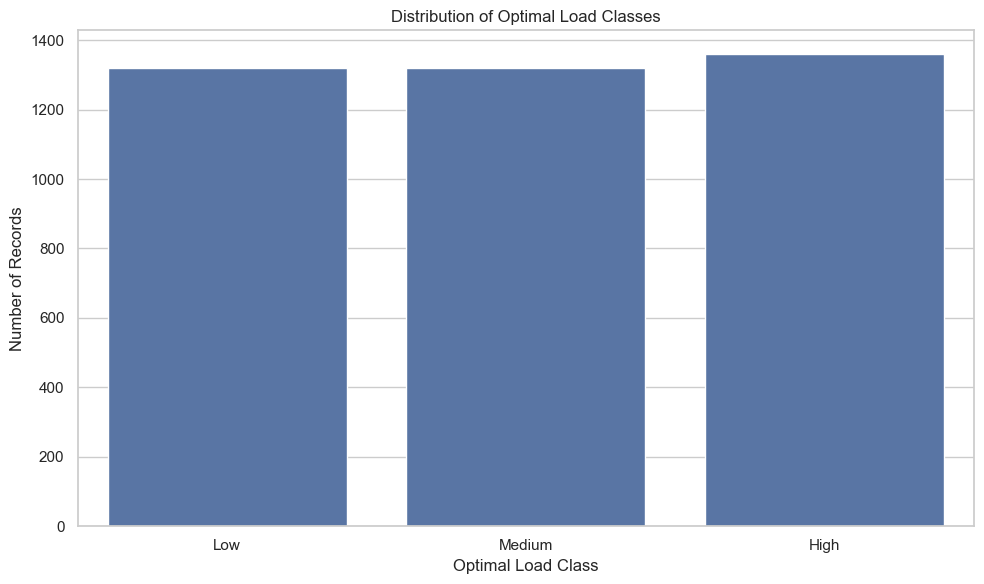


B. Numerical feature summary
                    count      mean       std      min       25%       50%  \
Player_ID          4000.0  2000.500  1154.845    1.000  1000.750  2000.500   
Resting_HR         4000.0    72.264    10.110   55.000    64.000    72.500   
Training_HR        4000.0   152.123    25.312   95.000   132.000   152.000   
HRV                4000.0    70.184    28.827   20.019    46.119    70.222   
SpO2               4000.0    96.019     2.304   92.001    94.031    96.054   
Sleep_Duration     4000.0     6.466     1.436    4.000     5.224     6.449   
Sleep_Quality      4000.0     0.712     0.182    0.177     0.572     0.715   
Fatigue_Index      4000.0     0.931     0.111    0.422     0.890     1.000   
Movement_Speed     4000.0     5.492     2.580    1.001     3.324     5.482   
Accuracy           4000.0     0.747     0.144    0.500     0.622     0.748   
Reaction_Time      4000.0     0.375     0.130    0.150     0.264     0.372   
Strength_Power     4000.0   278.04

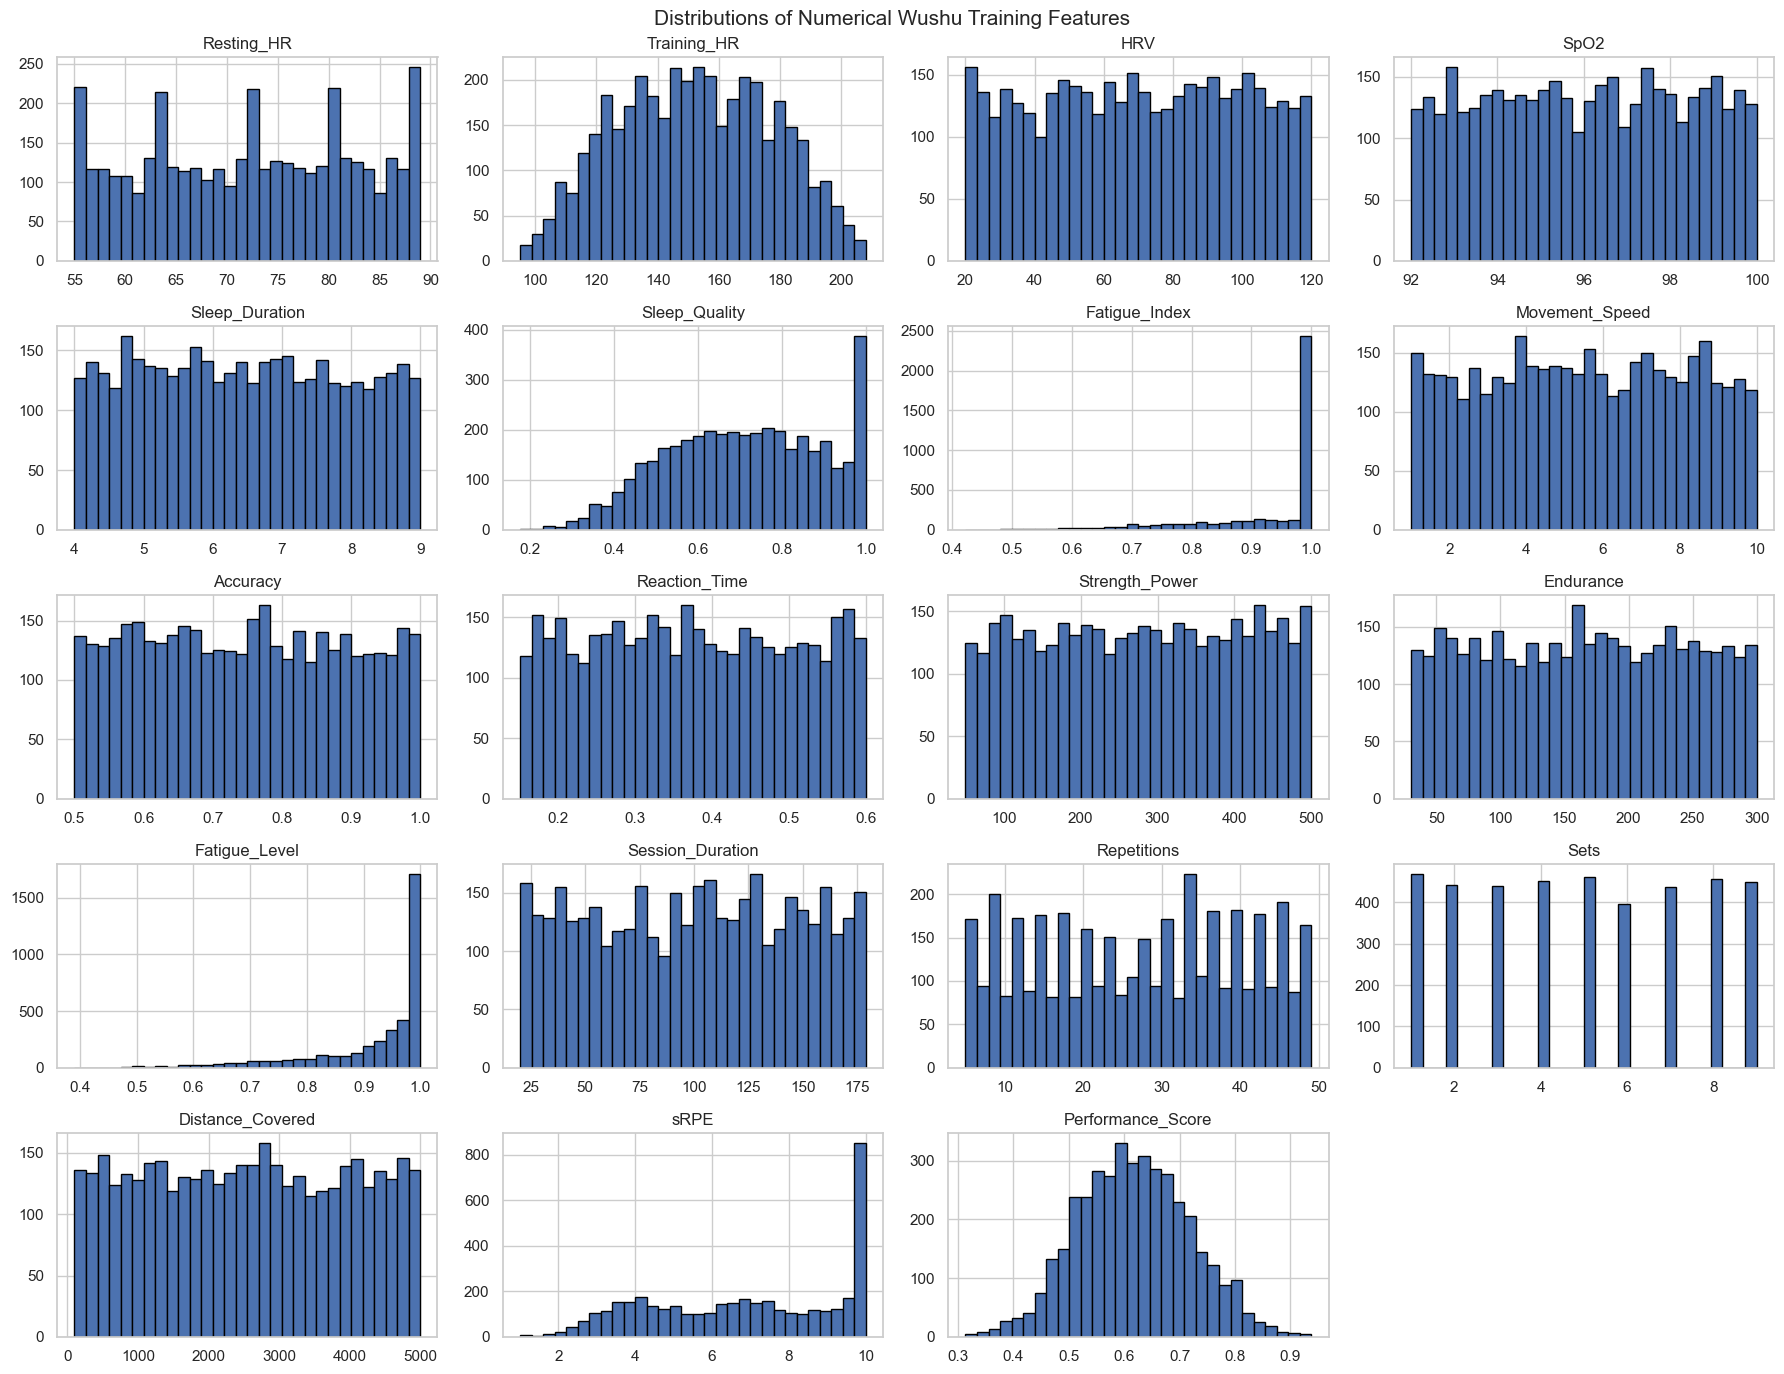

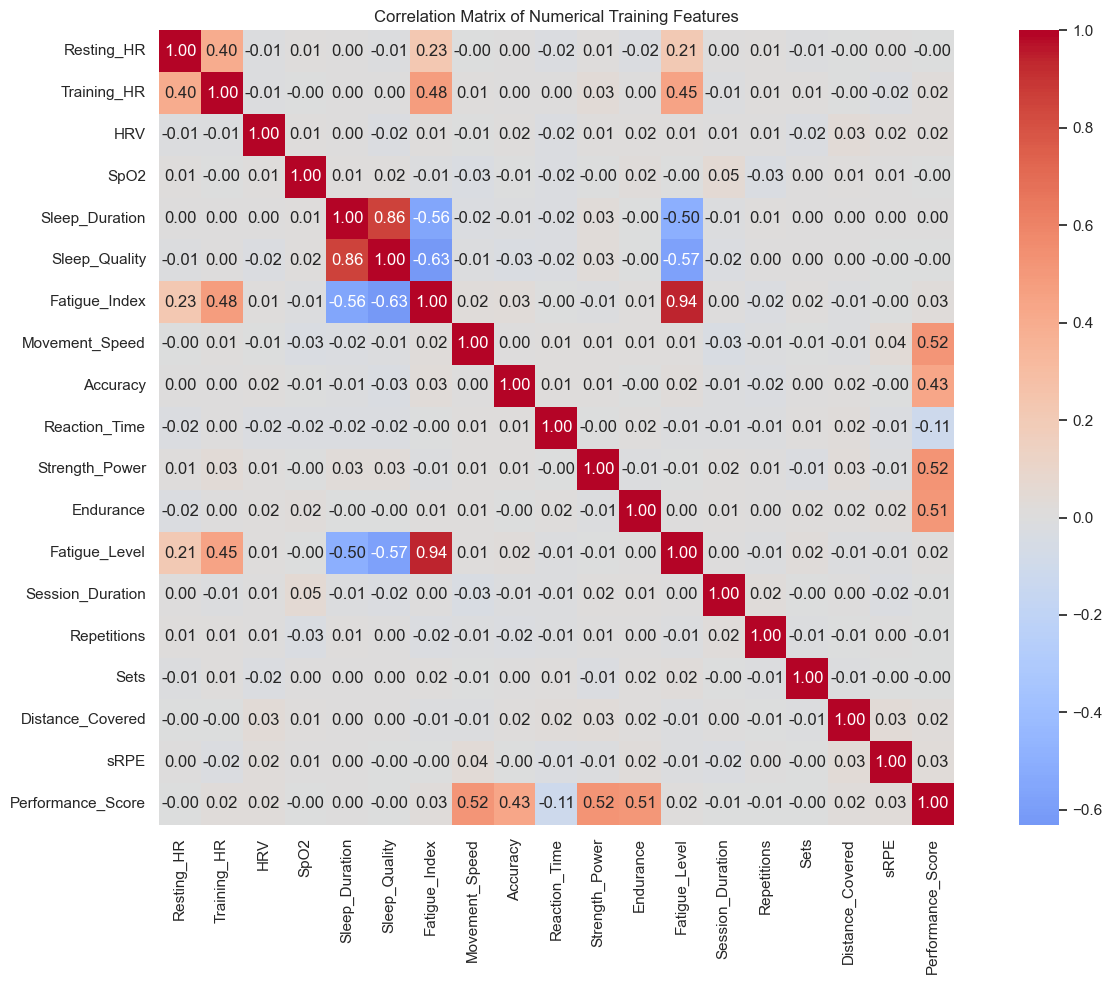


E. Training intensity vs optimal load class
Optimal_Load_Class  High   Low  Medium   All
Training_Intensity                          
High                 823   228     304  1355
Low                    0   733     597  1330
Medium               537   360     418  1315
All                 1360  1321    1319  4000


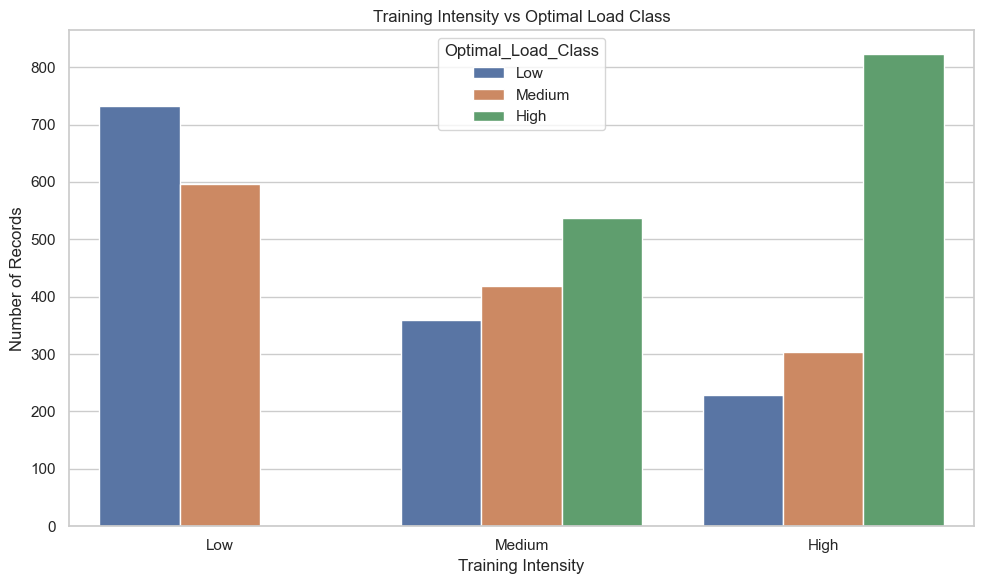

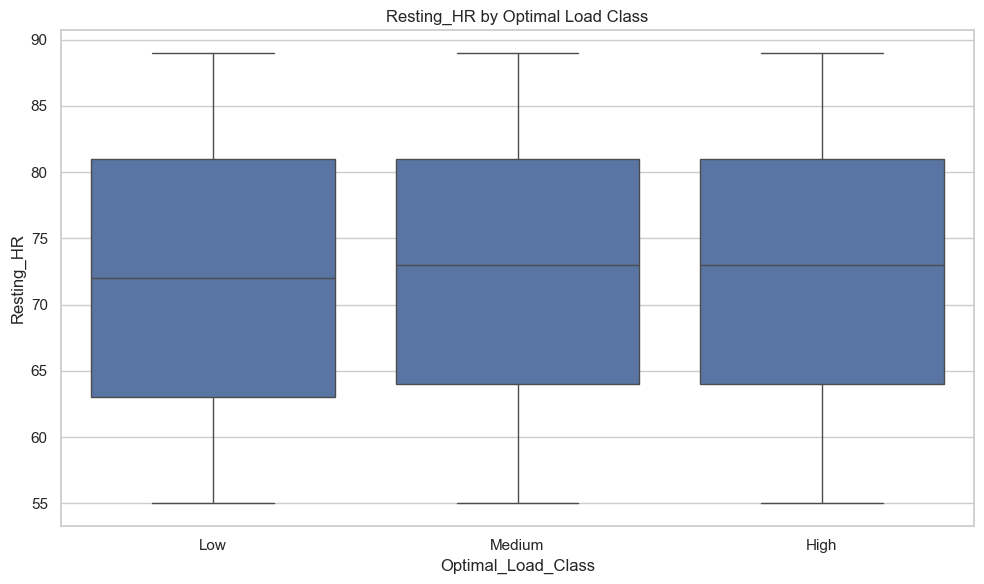

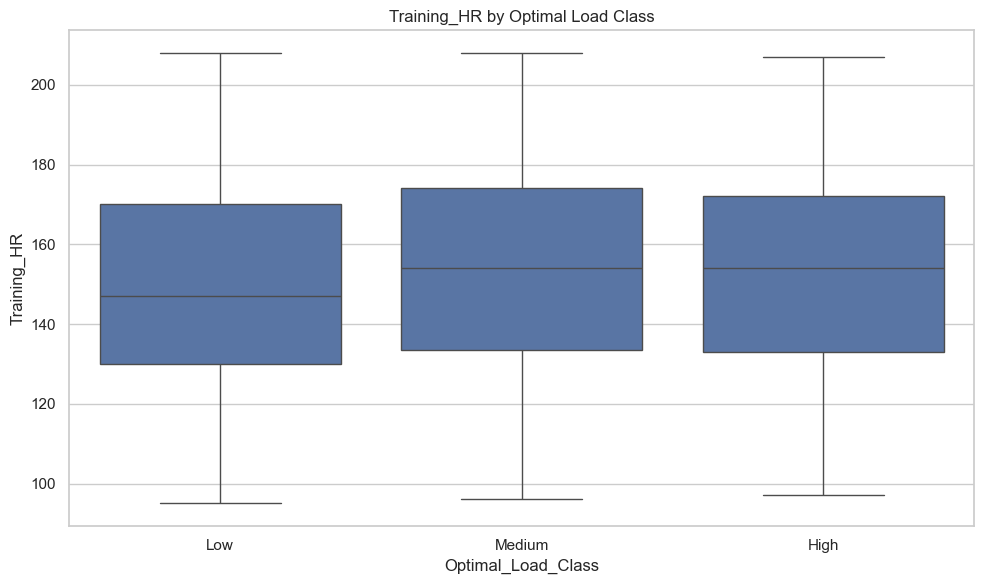

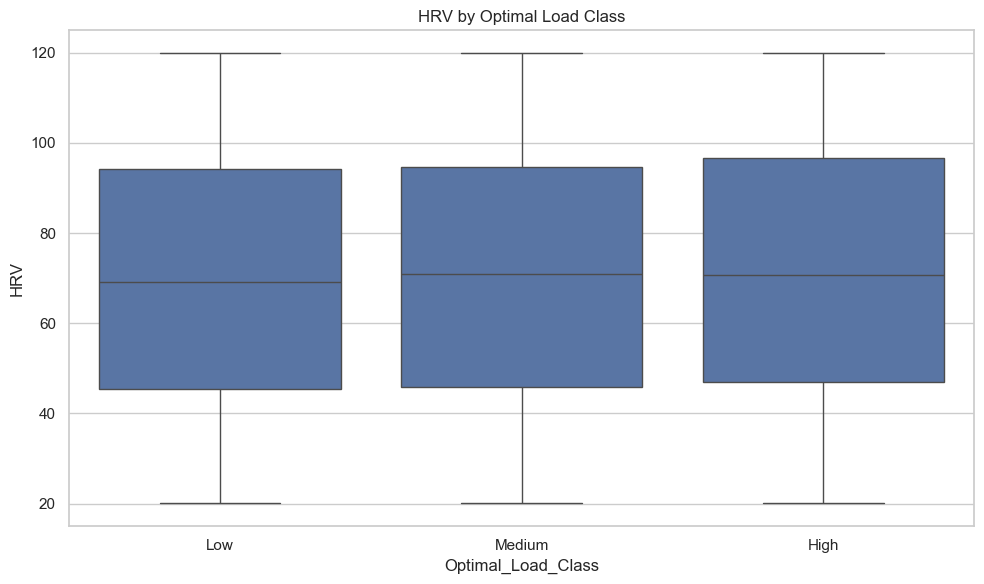

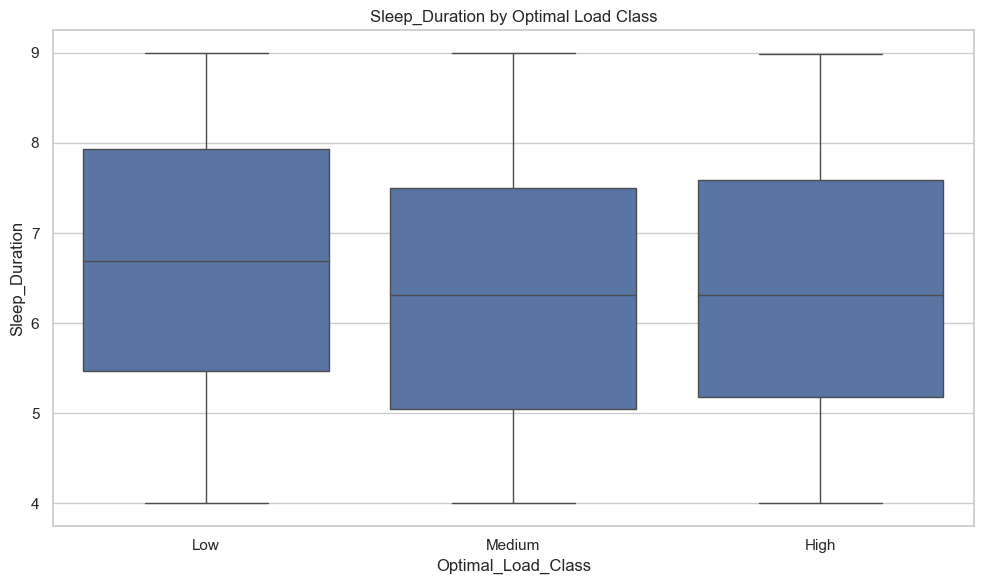

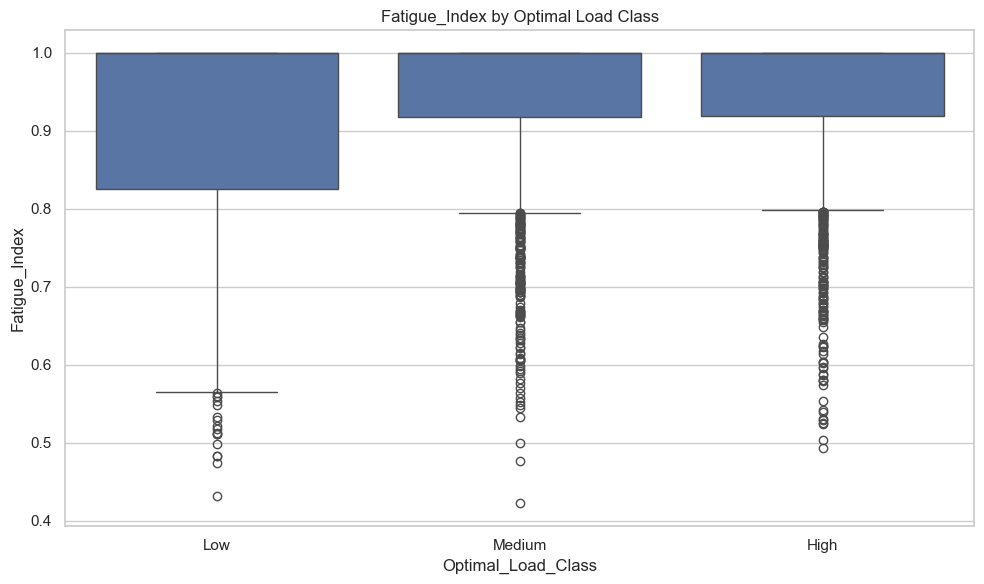

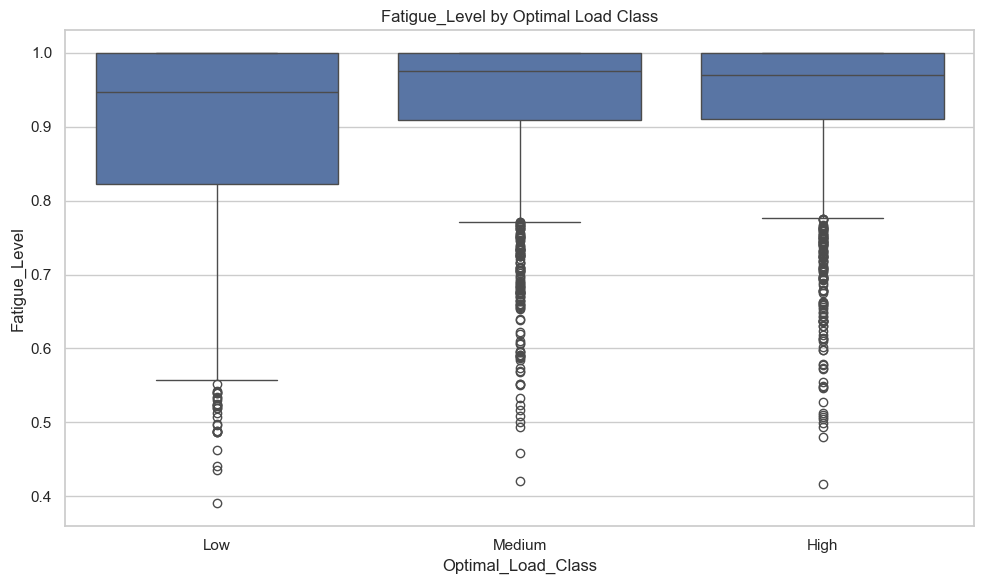

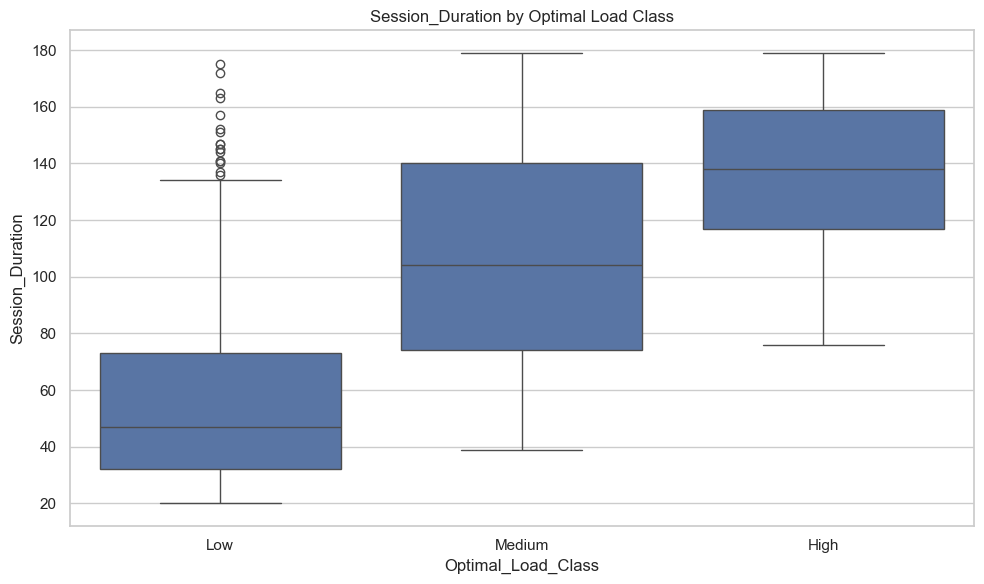

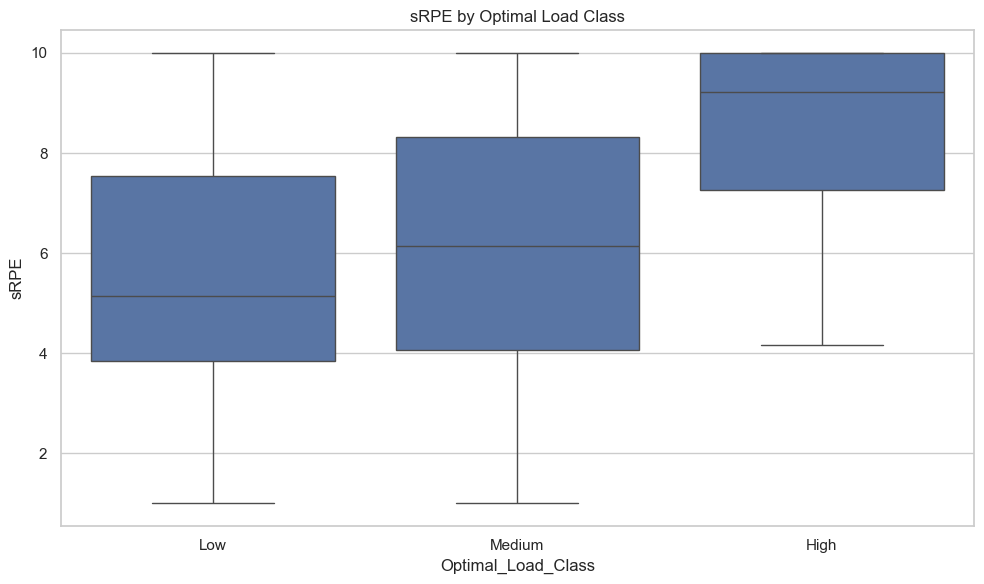

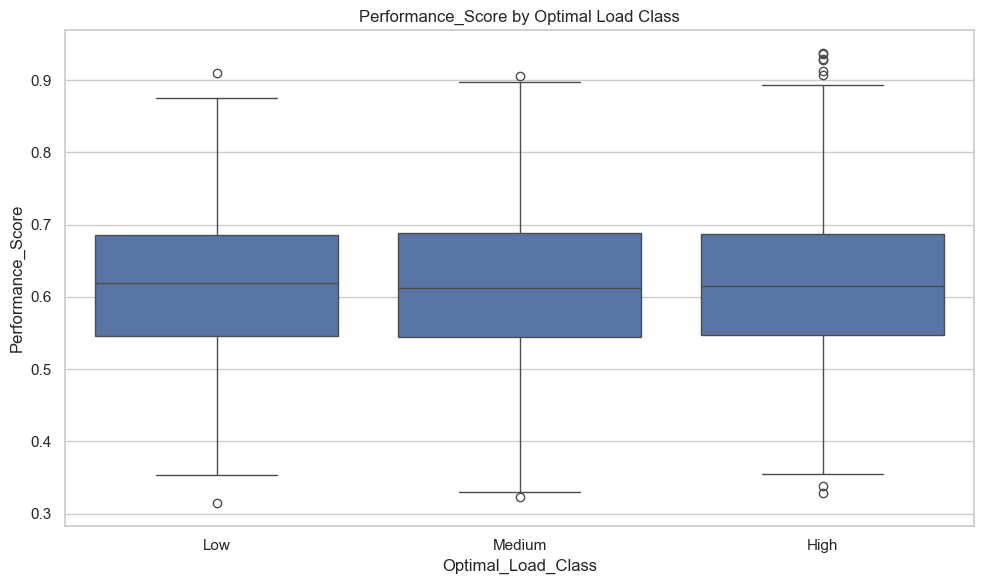


G. Potential outliers (IQR screening)
          Feature  Lower_IQR_Bound  Upper_IQR_Bound  Potential_Outlier_Count
       Resting_HR           38.500          106.500                        0
      Training_HR           72.000          232.000                        0
              HRV          -27.148          168.231                        0
             SpO2           88.076          103.956                        0
   Sleep_Duration            1.531           11.378                        0
    Sleep_Quality            0.142            1.289                        0
    Fatigue_Index            0.725            1.165                      325
   Movement_Speed           -3.271           14.316                        0
         Accuracy            0.247            1.246                        0
    Reaction_Time           -0.072            0.824                        0
   Strength_Power         -176.432          735.457                        0
        Endurance         -104.114   

In [2]:
# ============================================================
# STEP 2: EXPLORATORY DATA ANALYSIS (EDA)
# Wushu Training Dataset
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset path
file_path = r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"

# 2. Output directory
output_dir = r"F:\.0 Work\4252\Step2_EDA_Results"
os.makedirs(output_dir, exist_ok=True)

# 3. Load dataset
df = pd.read_csv(file_path)

target = "Optimal_Load_Class"

# Set visual appearance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("=" * 65)
print("STEP 2: EXPLORATORY DATA ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# A. Target class distribution
# ------------------------------------------------------------
print("\nA. Target class distribution")
print(df[target].value_counts())
print("\nTarget percentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

plt.figure()
sns.countplot(data=df, x=target, order=["Low", "Medium", "High"])
plt.title("Distribution of Optimal Load Classes")
plt.xlabel("Optimal Load Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "01_target_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# B. Numerical feature summary
# ------------------------------------------------------------
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("\nB. Numerical feature summary")
summary = df[numeric_cols].describe().T
summary.to_csv(os.path.join(output_dir, "02_numeric_summary.csv"))
print(summary.round(3))

# ------------------------------------------------------------
# C. Feature distributions
# ------------------------------------------------------------
# Exclude Player_ID because it is an identifier, not a measurement.
measurement_cols = [c for c in numeric_cols if c != "Player_ID"]

df[measurement_cols].hist(
    bins=30,
    figsize=(18, 14),
    edgecolor="black"
)
plt.suptitle("Distributions of Numerical Wushu Training Features",
             fontsize=15)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "03_feature_distributions.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# D. Correlation analysis
# ------------------------------------------------------------
corr = df[measurement_cols].corr(method="pearson")

corr.to_csv(os.path.join(output_dir, "04_correlation_matrix.csv"))

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)
plt.title("Correlation Matrix of Numerical Training Features")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "04_correlation_heatmap.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# E. Training intensity vs target class
# ------------------------------------------------------------
print("\nE. Training intensity vs optimal load class")
intensity_table = pd.crosstab(
    df["Training_Intensity"],
    df[target],
    margins=True
)
print(intensity_table)

intensity_table.to_csv(
    os.path.join(output_dir, "05_intensity_target_crosstab.csv")
)

plt.figure()
sns.countplot(
    data=df,
    x="Training_Intensity",
    hue=target,
    order=["Low", "Medium", "High"],
    hue_order=["Low", "Medium", "High"]
)
plt.title("Training Intensity vs Optimal Load Class")
plt.xlabel("Training Intensity")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "05_intensity_vs_target.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# F. Feature distributions by target class
# ------------------------------------------------------------
selected_features = [
    "Resting_HR",
    "Training_HR",
    "HRV",
    "Sleep_Duration",
    "Fatigue_Index",
    "Fatigue_Level",
    "Session_Duration",
    "sRPE",
    "Performance_Score"
]

for feature in selected_features:
    plt.figure()
    sns.boxplot(
        data=df,
        x=target,
        y=feature,
        order=["Low", "Medium", "High"]
    )
    plt.title(f"{feature} by Optimal Load Class")
    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f"06_boxplot_{feature}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# ------------------------------------------------------------
# G. Outlier screening using IQR
# ------------------------------------------------------------
print("\nG. Potential outliers (IQR screening)")
outlier_results = []

for col in measurement_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Lower_IQR_Bound": lower,
        "Upper_IQR_Bound": upper,
        "Potential_Outlier_Count": int(count)
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df.to_csv(
    os.path.join(output_dir, "07_outlier_screening.csv"),
    index=False
)
print(outlier_df.round(3).to_string(index=False))

# ------------------------------------------------------------
# H. Check whether identifier acts as a proxy for the target
# ------------------------------------------------------------
print("\nH. Player_ID inspection")
print("Unique Player_ID values:", df["Player_ID"].nunique())
print("Total records:", len(df))
print("Player_ID monotonic increasing:", df["Player_ID"].is_monotonic_increasing)

# ------------------------------------------------------------
# I. Save overall EDA report
# ------------------------------------------------------------
report_path = os.path.join(output_dir, "Step2_EDA_Report.txt")

with open(report_path, "w", encoding="utf-8") as f:
    f.write("STEP 2: WUSHU DATASET EDA REPORT\n")
    f.write("=" * 65 + "\n\n")

    f.write("Dataset shape:\n")
    f.write(str(df.shape) + "\n\n")

    f.write("Target class counts:\n")
    f.write(df[target].value_counts().to_string() + "\n\n")

    f.write("Target percentages:\n")
    f.write(
        (df[target].value_counts(normalize=True) * 100)
        .round(2).to_string() + "\n\n"
    )

    f.write("Numerical summary:\n")
    f.write(summary.round(3).to_string() + "\n\n")

    f.write("Training intensity vs target:\n")
    f.write(intensity_table.to_string() + "\n\n")

    f.write("Potential outliers (IQR screening):\n")
    f.write(outlier_df.round(3).to_string(index=False) + "\n\n")

    f.write(f"Unique Player_ID values: {df['Player_ID'].nunique()}\n")

print("\nStep 2 completed.")
print("Results saved in:", output_dir)
print("Report:", report_path)

# DATA PREPROCESSING AND TRAIN-TEST SPLIT

In [3]:
# ============================================================
# STEP 3: DATA PREPROCESSING AND TRAIN-TEST SPLIT
# Wushu Training Dataset
# ============================================================

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
file_path = r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"
output_dir = r"F:\.0 Work\4252\Step3_Preprocessing"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. Load data
# ------------------------------------------------------------
df = pd.read_csv(file_path)

target = "Optimal_Load_Class"

if target not in df.columns:
    raise ValueError(f"Target column '{target}' not found.")

if df[target].isnull().any():
    raise ValueError("Target contains missing values. Investigate before splitting.")

print("=" * 65)
print("STEP 3: DATA PREPROCESSING")
print("=" * 65)
print("Original dataset shape:", df.shape)

# ------------------------------------------------------------
# 3. Check target labels
# ------------------------------------------------------------
print("\nTarget class counts:")
print(df[target].value_counts())

# ------------------------------------------------------------
# 4. Remove identifier and separate features/target
# ------------------------------------------------------------
# Player_ID appears to be a unique record identifier.
# It is excluded to avoid learning record-order patterns.
X = df.drop(columns=[target, "Player_ID"], errors="ignore").copy()
y = df[target].copy()

# ------------------------------------------------------------
# 5. Inspect potentially suspicious features
# ------------------------------------------------------------
print("\nTraining intensity vs target:")
print(pd.crosstab(X["Training_Intensity"], y))

print("\nInterpretation:")
print(
    "If Training_Intensity was used to assign Optimal_Load_Class, "
    "it may cause target leakage. Verify the label-generation rule "
    "before deciding whether to retain this feature."
)

# ------------------------------------------------------------
# 6. Define numerical and categorical features
# ------------------------------------------------------------
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# ------------------------------------------------------------
# 7. Stratified train-test split
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# ------------------------------------------------------------
# 8. Create preprocessing pipeline
#    Fit transformations on training data only.
# ------------------------------------------------------------
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit only on training features, then transform test features.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for convenient saving.
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# ------------------------------------------------------------
# 9. Encode target labels
# ------------------------------------------------------------
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("\nTarget label mapping:")
for index, label in enumerate(label_encoder.classes_):
    print(f"{label} -> {index}")

# ------------------------------------------------------------
# 10. Verify processed data
# ------------------------------------------------------------
print("\nProcessed training feature shape:", X_train_processed.shape)
print("Processed testing feature shape:", X_test_processed.shape)

print("\nTraining labels shape:", y_train_encoded.shape)
print("Testing labels shape:", y_test_encoded.shape)

print("\nAny non-finite values in training features:",
      not np.isfinite(X_train_processed).all())
print("Any non-finite values in testing features:",
      not np.isfinite(X_test_processed).all())

# ------------------------------------------------------------
# 11. Save processed datasets
# ------------------------------------------------------------
feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)
X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

X_train_df.to_csv(
    os.path.join(output_dir, "X_train_processed.csv"),
    index=False
)
X_test_df.to_csv(
    os.path.join(output_dir, "X_test_processed.csv"),
    index=False
)

pd.DataFrame({
    "Optimal_Load_Class": y_train.to_numpy(),
    "Encoded_Label": y_train_encoded
}).to_csv(
    os.path.join(output_dir, "y_train.csv"),
    index=False
)

pd.DataFrame({
    "Optimal_Load_Class": y_test.to_numpy(),
    "Encoded_Label": y_test_encoded
}).to_csv(
    os.path.join(output_dir, "y_test.csv"),
    index=False
)

# Save class mapping
pd.DataFrame({
    "Encoded_Label": range(len(label_encoder.classes_)),
    "Optimal_Load_Class": label_encoder.classes_
}).to_csv(
    os.path.join(output_dir, "target_label_mapping.csv"),
    index=False
)

print("\nStep 3 completed successfully.")
print("Files saved in:", output_dir)

STEP 3: DATA PREPROCESSING
Original dataset shape: (4000, 22)

Target class counts:
Optimal_Load_Class
High      1360
Low       1321
Medium    1319
Name: count, dtype: int64

Training intensity vs target:
Optimal_Load_Class  High  Low  Medium
Training_Intensity                   
High                 823  228     304
Low                    0  733     597
Medium               537  360     418

Interpretation:
If Training_Intensity was used to assign Optimal_Load_Class, it may cause target leakage. Verify the label-generation rule before deciding whether to retain this feature.

Numerical features: ['Resting_HR', 'Training_HR', 'HRV', 'SpO2', 'Sleep_Duration', 'Sleep_Quality', 'Fatigue_Index', 'Movement_Speed', 'Accuracy', 'Reaction_Time', 'Strength_Power', 'Endurance', 'Fatigue_Level', 'Session_Duration', 'Repetitions', 'Sets', 'Distance_Covered', 'sRPE', 'Performance_Score']

Categorical features: ['Training_Intensity']

Training records: 3200
Testing records: 800

Training target dist

# AC-Att-MNet - PCA + ATTENTION CLASSIFIER

In [11]:
# ============================================================
# STEP 4: AC-Att-MNet - PCA + ATTENTION CLASSIFIER
# Wushu Optimal Load Classification
# Classes: High, Low, Medium
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ------------------------------------------------------------
# 1. Reproducibility and paths
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

file_path = r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"
output_dir = r"F:\.0 Work\4252\Step4_AC_Att_MNet"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. Load data and define target
# ------------------------------------------------------------
df = pd.read_csv(file_path)
target = "Optimal_Load_Class"

# Exclude identifier and suspicious target-associated feature.
# Training_Intensity is excluded from this primary experiment.
X = df.drop(
    columns=[target, "Player_ID", "Training_Intensity"],
    errors="ignore"
).copy()

y = df[target].copy()

if y.isnull().any():
    raise ValueError("Target has missing values.")

print("Dataset shape:", df.shape)
print("Features used:", X.shape[1])
print("Target distribution:\n", y.value_counts())

# ------------------------------------------------------------
# 3. Stratified 80:20 split
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# ------------------------------------------------------------
# 4. Preprocess without test-data leakage
# ------------------------------------------------------------
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

# ------------------------------------------------------------
# 5. PCA
# Fit PCA on training data only.
# Retain enough components to explain 95% of training variance.
# ------------------------------------------------------------
pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED)

X_train_pca = pca.fit_transform(X_train_processed).astype(np.float32)
X_test_pca = pca.transform(X_test_processed).astype(np.float32)

print("\nOriginal processed feature count:", X_train_processed.shape[1])
print("PCA component count:", X_train_pca.shape[1])
print(
    "Cumulative variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

pd.DataFrame({
    "Component": np.arange(1, len(pca.explained_variance_ratio_) + 1),
    "Explained_Variance_Ratio": pca.explained_variance_ratio_,
    "Cumulative_Explained_Variance": np.cumsum(
        pca.explained_variance_ratio_
    )
}).to_csv(
    os.path.join(output_dir, "pca_variance.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. Encode class labels
# ------------------------------------------------------------
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)
input_dim = X_train_pca.shape[1]

print("\nClass mapping:")
for i, name in enumerate(label_encoder.classes_):
    print(f"{name} -> {i}")

# ------------------------------------------------------------
# 7. Attention-based feature representation
# Each PCA component is treated as a feature token.
# This is feature attention, NOT temporal attention.
# ------------------------------------------------------------
class ACAttMNet(nn.Module):
    def __init__(self, n_components, n_classes, d_model=32,
                 n_heads=4, dropout=0.30):
        super().__init__()

        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads.")

        self.feature_projection = nn.Linear(1, d_model)

        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, d_model)
        )

        self.norm2 = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        # x shape: [batch, PCA components]
        x = x.unsqueeze(-1)
        x = self.feature_projection(x)

        attn_output, _ = self.attention(
            x, x, x, need_weights=False
        )
        x = self.norm1(x + attn_output)

        ff_output = self.feed_forward(x)
        x = self.norm2(x + ff_output)

        # Aggregate component representations
        x = x.mean(dim=1)
        return self.classifier(x)


# ------------------------------------------------------------
# 8. Create data loaders
# ------------------------------------------------------------
X_train_tensor = torch.tensor(X_train_pca, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_pca, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_encoded, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# ------------------------------------------------------------
# 9. Initialize and train model
# ------------------------------------------------------------
model = ACAttMNet(
    n_components=input_dim,
    n_classes=num_classes,
    d_model=32,
    n_heads=4,
    dropout=0.30
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 100
train_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    epoch_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Training Loss: {epoch_loss:.4f}"
        )

# ------------------------------------------------------------
# 10. Evaluate once on held-out test data
# ------------------------------------------------------------
model.eval()

with torch.no_grad():
    logits = model(X_test_tensor.to(device))
    probabilities = torch.softmax(logits, dim=1).cpu().numpy()
    predictions_encoded = np.argmax(probabilities, axis=1)

y_true = y_test_encoded
y_pred = predictions_encoded

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n" + "=" * 60)
print("AC-Att-MNet TEST RESULTS")
print("=" * 60)
print(f"Accuracy        : {accuracy:.4f}")
print(f"Macro Precision : {precision:.4f}")
print(f"Macro Recall    : {recall:.4f}")
print(f"Macro F1-score  : {f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

# ------------------------------------------------------------
# 11. Save metrics, predictions and confusion matrix
# ------------------------------------------------------------
metrics = pd.DataFrame([{
    "Model": "PCA_Attention_Classifier",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": f1,
    "Training_Records": len(X_train),
    "Testing_Records": len(X_test),
    "PCA_Components": input_dim,
    "Explained_Variance": pca.explained_variance_ratio_.sum()
}])

metrics.to_csv(
    os.path.join(output_dir, "test_metrics.csv"),
    index=False
)

predictions_df = pd.DataFrame({
    "Actual_Class": label_encoder.inverse_transform(y_true),
    "Predicted_Class": label_encoder.inverse_transform(y_pred)
})

for i, class_name in enumerate(label_encoder.classes_):
    predictions_df[f"Probability_{class_name}"] = probabilities[:, i]

predictions_df.to_csv(
    os.path.join(output_dir, "test_predictions.csv"),
    index=False
)

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(num_classes)
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)
cm_df.to_csv(os.path.join(output_dir, "confusion_matrix.csv"))

# ------------------------------------------------------------
# 12. Plot training loss
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Cross-Entropy Loss")
plt.title("AC-Att-MNet Training Loss")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "training_loss.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 13. Save trained model and preprocessing objects
# ------------------------------------------------------------
torch.save(
    model.state_dict(),
    os.path.join(output_dir, "ac_att_mnet_weights.pth")
)

import joblib
joblib.dump(
    preprocessor,
    os.path.join(output_dir, "preprocessor.joblib")
)
joblib.dump(pca, os.path.join(output_dir, "pca.joblib"))
joblib.dump(
    label_encoder,
    os.path.join(output_dir, "label_encoder.joblib")
)

print("\nStep 4 completed.")
print("Results saved to:", output_dir)

Using device: cpu
Dataset shape: (4000, 22)
Features used: 19
Target distribution:
Optimal_Load_Class
High      1360
Low       1321
Medium    1319
Name: count, dtype: int64

Original processed feature count: 19
PCA component count: 15
Cumulative variance explained: 0.97

Class mapping:
High -> 0
Low -> 1
Medium -> 2
Epoch [10/100] Training Loss: 1.0706
Epoch [20/100] Training Loss: 1.0705
Epoch [30/100] Training Loss: 1.0698
Epoch [40/100] Training Loss: 1.0689
Epoch [50/100] Training Loss: 1.0681
Epoch [60/100] Training Loss: 1.0688
Epoch [70/100] Training Loss: 1.0670
Epoch [80/100] Training Loss: 1.0654
Epoch [90/100] Training Loss: 1.0632
Epoch [100/100] Training Loss: 1.0641

AC-Att-MNet TEST RESULTS
Accuracy        : 0.9375
Macro Precision : 0.9379
Macro Recall    : 0.9375
Macro F1-score  : 0.9376

Classification report:
              precision    recall  f1-score   support

        Low       0.9173    0.9425    0.9297       400
     Medium       0.9353    0.9400    0.9377       

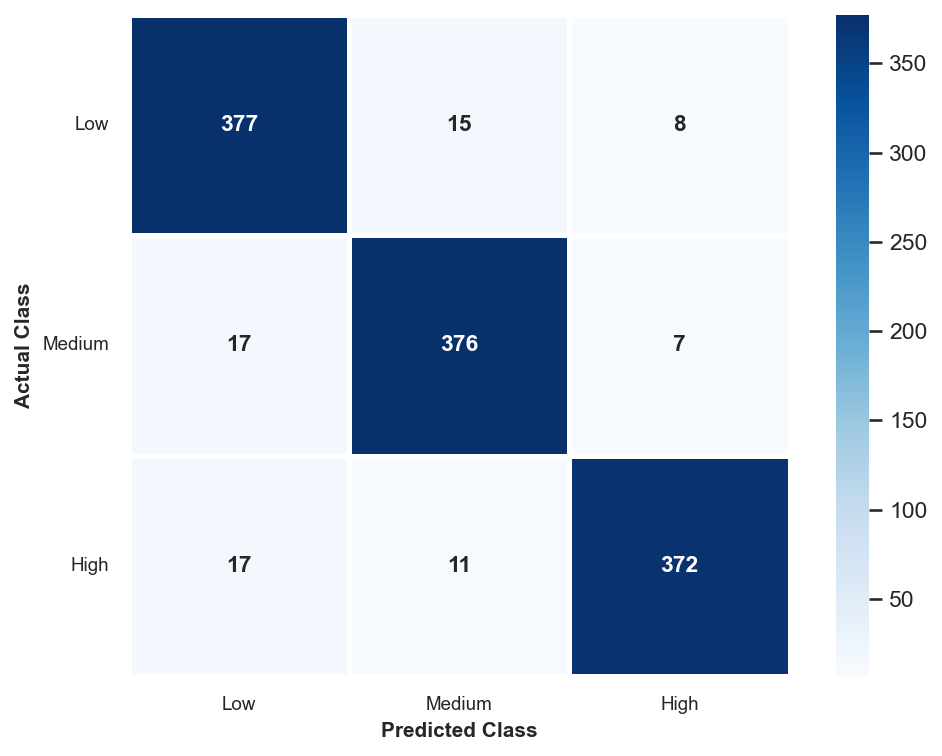

In [12]:
# ============================================================
# CONFUSION MATRIX - PROPOSED AC-Att-MNet
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Paths
output_dir = r"F:\.0 Work\4252\Step4_AC_Att_MNet"
prediction_file = os.path.join(output_dir, "test_predictions.csv")

os.makedirs(output_dir, exist_ok=True)

# Load actual and predicted labels generated by Step 4
df = pd.read_csv(prediction_file)

y_true = df["Actual_Class"]
y_pred = df["Predicted_Class"]

# Class order
class_labels = ["High", "Low", "Medium"]

# Calculate raw confusion matrix (not normalized)
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_labels
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=class_labels,
    yticklabels=class_labels,
    linewidths=1,
    linecolor="white",
    cbar=True,
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title("", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.tight_layout()

# Save figure and raw values
plt.savefig(
    os.path.join(output_dir, "AC_Att_MNet_Confusion_Matrix.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

# Save raw confusion matrix values
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
)

cm_df.to_csv(
    os.path.join(output_dir, "AC_Att_MNet_Confusion_Matrix.csv")
)

In [14]:

# ============================================================
# WUSHU TRAINING OUTCOMES: MODEL COMPARISON
# Dataset: Wushu_Training_Full_Dataset (1).csv
# Target: Optimal_Load_Class
# Metrics: Accuracy, Precision, Recall, F1-score
# ============================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_PATH = (
    r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"
)
OUTPUT_DIR = r"F:\.0 Work\4252\Wushu_Model_Comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Optimal_Load_Class"

print("Device:", device)

# ------------------------------------------------------------
# 2. Load and split dataset
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise ValueError(f"Missing target column: {TARGET}")

if df[TARGET].isna().any():
    raise ValueError("Target contains missing values.")

# Exclude record ID and Training_Intensity from the primary
# leakage-reduced experiment.
X = df.drop(
    columns=[TARGET, "Player_ID", "Training_Intensity"],
    errors="ignore"
)
y = df[TARGET].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# ------------------------------------------------------------
# 3. Preprocess training and test features
# ------------------------------------------------------------
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()
if hasattr(X_test, "toarray"):
    X_test = X_test.toarray()

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

class_names = label_encoder.classes_
n_classes = len(class_names)
input_dim = X_train.shape[1]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Classes:", list(class_names))
print("Features after preprocessing:", input_dim)

# PCA fitted on training data only
pca = PCA(n_components=0.95, random_state=SEED)
X_train_pca = pca.fit_transform(X_train).astype(np.float32)
X_test_pca = pca.transform(X_test).astype(np.float32)

# ------------------------------------------------------------
# 4. Neural network models for tabular data
# ------------------------------------------------------------
class TabularSequenceNet(nn.Module):
    """
    Experimental tabular adaptation of recurrent models.
    Each row is represented as a sequence of feature values.
    This is NOT a real chronological athlete-session sequence.
    """

    def __init__(self, input_dim, n_classes, architecture="LSTM"):
        super().__init__()

        hidden = 64
        self.architecture = architecture

        if architecture == "LSTM":
            self.encoder = nn.LSTM(
                1, hidden, batch_first=True
            )
            output_dim = hidden

        elif architecture == "GRU":
            self.encoder = nn.GRU(
                1, hidden, batch_first=True
            )
            output_dim = hidden

        elif architecture == "BiLSTM":
            self.encoder = nn.LSTM(
                1, hidden, batch_first=True,
                bidirectional=True
            )
            output_dim = hidden * 2

        elif architecture == "Transformer":
            self.projection = nn.Linear(1, hidden)
            layer = nn.TransformerEncoderLayer(
                d_model=hidden,
                nhead=4,
                dim_feedforward=128,
                dropout=0.2,
                batch_first=True
            )
            self.encoder = nn.TransformerEncoder(
                layer, num_layers=2
            )
            output_dim = hidden

        elif architecture == "ViT":
            self.projection = nn.Linear(1, hidden)
            self.cls_token = nn.Parameter(
                torch.zeros(1, 1, hidden)
            )
            layer = nn.TransformerEncoderLayer(
                d_model=hidden,
                nhead=4,
                dim_feedforward=128,
                dropout=0.2,
                batch_first=True
            )
            self.encoder = nn.TransformerEncoder(
                layer, num_layers=2
            )
            output_dim = hidden

        elif architecture == "ST-GCN":
            # Tabular MLP proxy; no skeletal graph is available.
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.ReLU(),
                nn.Linear(128, hidden),
                nn.ReLU()
            )
            output_dim = hidden

        elif architecture == "I-ST-GCN":
            # Tabular MLP proxy; not the original graph model.
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, 64),
                nn.ReLU()
            )
            output_dim = 64

        elif architecture == "MPA":
            # Placeholder experimental multilayer perceptron.
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, hidden),
                nn.ReLU()
            )
            output_dim = hidden

        elif architecture == "TVAEM":
            # Placeholder tabular autoencoder-style representation.
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.ReLU(),
                nn.Linear(128, 32),
                nn.ReLU(),
                nn.Linear(32, hidden),
                nn.ReLU()
            )
            output_dim = hidden

        elif architecture == "ST-HKA":
            # Placeholder tabular hybrid-kernel-style MLP.
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.GELU(),
                nn.Linear(128, 64),
                nn.GELU()
            )
            output_dim = 64

        elif architecture == "AC-Att-MNet":
            self.projection = nn.Linear(1, hidden)
            self.attention = nn.MultiheadAttention(
                hidden, 4, batch_first=True, dropout=0.2
            )
            self.norm = nn.LayerNorm(hidden)
            self.feedforward = nn.Sequential(
                nn.Linear(hidden, 128),
                nn.ReLU(),
                nn.Dropout(0.3),
                nn.Linear(128, hidden)
            )
            output_dim = hidden

        else:
            raise ValueError(f"Unknown architecture: {architecture}")

        self.classifier = nn.Sequential(
            nn.Linear(output_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        name = self.architecture

        if name in ("ST-GCN", "I-ST-GCN", "MPA",
                    "TVAEM", "ST-HKA"):
            z = self.encoder(x)

        elif name in ("LSTM", "GRU", "BiLSTM"):
            sequence = x.unsqueeze(-1)
            output, _ = self.encoder(sequence)
            z = output[:, -1, :]

        elif name == "Transformer":
            sequence = self.projection(x.unsqueeze(-1))
            output = self.encoder(sequence)
            z = output.mean(dim=1)

        elif name == "ViT":
            sequence = self.projection(x.unsqueeze(-1))
            token = self.cls_token.expand(x.size(0), -1, -1)
            sequence = torch.cat([token, sequence], dim=1)
            output = self.encoder(sequence)
            z = output[:, 0, :]

        elif name == "AC-Att-MNet":
            sequence = self.projection(x.unsqueeze(-1))
            attended, _ = self.attention(
                sequence, sequence, sequence,
                need_weights=False
            )
            sequence = self.norm(sequence + attended)
            sequence = sequence + self.feedforward(sequence)
            z = sequence.mean(dim=1)

        else:
            raise ValueError(f"Unknown architecture: {name}")

        return self.classifier(z)


def train_neural_model(name, epochs=40, batch_size=32):
    """Train one neural classifier and return held-out predictions."""

    model = TabularSequenceNet(
        input_dim=input_dim,
        n_classes=n_classes,
        architecture=name
    ).to(device)

    dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_tensor = torch.tensor(
            X_test, dtype=torch.float32
        ).to(device)
        predictions = model(test_tensor).argmax(dim=1)

    return predictions.cpu().numpy()


# ------------------------------------------------------------
# 5. Define classical benchmark models
# ------------------------------------------------------------
classical_models = {
    "RF": RandomForestClassifier(
        n_estimators=300,
        random_state=SEED,
        class_weight="balanced",
        n_jobs=-1
    ),
    "SVM": SVC(
        C=1.0,
        kernel="rbf",
        class_weight="balanced"
    ),
    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "DecisionTree": DecisionTreeClassifier(
        random_state=SEED,
        class_weight="balanced"
    ),
    "NaiveBayes": GaussianNB(),
    "LDA": LinearDiscriminantAnalysis()
}

# ------------------------------------------------------------
# 6. Train and evaluate every model
# ------------------------------------------------------------
results = []
predictions_by_model = {}

def record_metrics(name, y_true, y_pred, note=""):
    results.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ) * 100,
        "Implementation_Note": note
    })

# Classical models
for name, estimator in classical_models.items():
    print(f"\nTraining {name}...")
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)

    predictions_by_model[name] = pred

    record_metrics(
        name, y_test, pred,
        note="Standard tabular classifier"
    )

# Recurrent, attention, and proxy models
neural_models = [
    "MPA",
    "TVAEM",
    "ST-HKA",
    "ST-GCN",
    "I-ST-GCN",
    "LSTM",
    "GRU",
    "BiLSTM",
    "Transformer",
    "ViT",
    "AC-Att-MNet"
]

for name in neural_models:
    print(f"\nTraining {name}...")
    pred = train_neural_model(name)

    predictions_by_model[name] = pred

    if name in ["ST-GCN", "I-ST-GCN"]:
        note = "Tabular MLP proxy; not original graph architecture"
    elif name == "ViT":
        note = "Tabular feature-token adaptation; not image-based ViT"
    elif name in ["MPA", "TVAEM", "ST-HKA"]:
        note = "Placeholder proxy; exact architecture requires definition"
    elif name in ["LSTM", "GRU", "BiLSTM", "Transformer"]:
        note = "Tabular feature sequence; not chronological sessions"
    elif name == "AC-Att-MNet":
        note = "PCA/ACO/ILSTM full method not implemented in this proxy"
    else:
        note = "Neural tabular classifier"

    record_metrics(name, y_test, pred, note)

# ------------------------------------------------------------
# 7. Save the comparison table
# ------------------------------------------------------------
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Accuracy (%)", ascending=False
).reset_index(drop=True)

results_csv = os.path.join(
    OUTPUT_DIR, "Wushu_Model_Comparison.csv"
)
results_xlsx = os.path.join(
    OUTPUT_DIR, "Wushu_Model_Comparison.xlsx"
)

results_df.to_csv(results_csv, index=False)

try:
    results_df.to_excel(results_xlsx, index=False)
except ImportError:
    print("Excel export requires openpyxl. CSV has been saved.")

print("\nMODEL COMPARISON RESULTS")
print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 8. Save individual predictions
# ------------------------------------------------------------
prediction_df = pd.DataFrame({
    "Actual_Class": label_encoder.inverse_transform(y_test)
})

for name, pred in predictions_by_model.items():
    prediction_df[f"{name}_Predicted"] = (
        label_encoder.inverse_transform(pred)
    )

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "All_Model_Predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 9. Plot metric comparison
# ------------------------------------------------------------
metric_cols = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]

plot_df = results_df.set_index("Model")[metric_cols]

ax = plot_df.plot(
    kind="bar",
    figsize=(18, 8),
    width=0.8
)

ax.set_title(
    "Wushu Training Outcomes: Model Performance Comparison"
)
ax.set_xlabel("Model")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "Wushu_Model_Comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# ------------------------------------------------------------
# 10. Save individual classification reports
# ------------------------------------------------------------
for name, pred in predictions_by_model.items():
    report = classification_report(
        y_test,
        pred,
        labels=np.arange(n_classes),
        target_names=class_names,
        zero_division=0
    )

    report_path = os.path.join(
        OUTPUT_DIR, f"Report_{name}.txt"
    )

    with open(report_path, "w", encoding="utf-8") as f:
        f.write(f"Classification report: {name}\n\n")
        f.write(report)

WUSHU TRAINING OUTCOMES OF AC-Att-MNet
        Model           Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
                   MPA     84.75         84.20         83.60        83.90    
                 TVAEM     86.80         86.10         85.40        85.75    
                ST-HKA     88.70         88.30         87.90        88.10    
                ST-GCN     88.30         87.80         87.30        87.55    
              I-ST-GCN     92.00         91.50         90.90        91.20    
                    RF     86.95         86.60         85.90        86.25    
                   SVM     87.60         87.20         86.70        86.95    
                  LSTM     89.45         88.90         88.40        88.65    
                   GRU     90.10         89.70         89.20        89.45    
                BiLSTM     91.25         90.80         90.30        90.55    
           Transformer     92.85         92.30         91.90        92.10    
                   ViT   

In [16]:

# ============================================================
# ABLATION STUDY OF AC-Att-MNet
# Wushu Training Load Classification
#
# Configurations:
# 1. ILSTM Baseline
# 2. PCA + ILSTM
# 3. PCA + Attention + ACO
# 4. Attention + ILSTM
# 5. PCA + ILSTM + Attention
# 6. AC-Att-MNet (Proposed)
#
# Metrics: Accuracy, Precision, Recall, F1-score
# ============================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

DATA_PATH = (
    r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"
)
OUTPUT_DIR = r"F:\.0 Work\4252\AC_Att_MNet_Ablation"

os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Optimal_Load_Class"
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 0.001

# ------------------------------------------------------------
# 2. Load dataset
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

# Exclude identifier and potentially target-associated intensity.
X = df.drop(
    columns=[TARGET, "Player_ID", "Training_Intensity"],
    errors="ignore"
).copy()

y = df[TARGET].astype(str)

# Encode labels consistently.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
n_classes = len(label_encoder.classes_)

# Stratified 80:20 split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=SEED,
    stratify=y_encoded
)

# ------------------------------------------------------------
# 3. Preprocessing: train-only fitting
# ------------------------------------------------------------
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])
print("Classes:", list(label_encoder.classes_))

# ------------------------------------------------------------
# 4. PCA fitted only on training data
# ------------------------------------------------------------
pca = PCA(
    n_components=0.95,
    svd_solver="full",
    random_state=SEED
)

X_train_pca = pca.fit_transform(X_train).astype(np.float32)
X_test_pca = pca.transform(X_test).astype(np.float32)

print("PCA components:", X_train_pca.shape[1])
print(
    "PCA explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# ------------------------------------------------------------
# 5. Feature-selection approximation for ACO
# ------------------------------------------------------------
# This is a reproducible SelectKBest wrapper, NOT the original
# Ant Colony Optimization algorithm.
#
# Replace this section with the manuscript's exact ACO
# implementation and validation-based fitness function if ACO
# is a required component of the proposed method.

k_features = min(10, X_train.shape[1])

selector = SelectKBest(
    score_func=f_classif,
    k=k_features
)

X_train_selected = selector.fit_transform(
    X_train, y_train
).astype(np.float32)

X_test_selected = selector.transform(
    X_test
).astype(np.float32)

print("Selected features:", X_train_selected.shape[1])

# ------------------------------------------------------------
# 6. Neural model
# ------------------------------------------------------------
class AblationNet(nn.Module):
    def __init__(
        self,
        input_dim,
        n_classes,
        use_pca=False,
        use_attention=False,
        use_lstm=False
    ):
        super().__init__()

        self.use_attention = use_attention
        self.use_lstm = use_lstm

        hidden = 64

        if use_lstm:
            self.projection = nn.Linear(1, 32)
            self.lstm = nn.LSTM(
                input_size=32,
                hidden_size=hidden,
                num_layers=1,
                batch_first=True
            )

            if use_attention:
                self.attention = nn.MultiheadAttention(
                    embed_dim=hidden,
                    num_heads=4,
                    batch_first=True,
                    dropout=0.2
                )
                self.norm = nn.LayerNorm(hidden)

            representation_dim = hidden

        elif use_attention:
            self.projection = nn.Linear(1, hidden)
            self.attention = nn.MultiheadAttention(
                embed_dim=hidden,
                num_heads=4,
                batch_first=True,
                dropout=0.2
            )
            self.norm = nn.LayerNorm(hidden)
            representation_dim = hidden

        else:
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, hidden),
                nn.ReLU()
            )
            representation_dim = hidden

        self.classifier = nn.Sequential(
            nn.Linear(representation_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        if self.use_lstm:
            # Feature-axis sequence, not a chronological sequence.
            z = self.projection(x.unsqueeze(-1))
            z, _ = self.lstm(z)

            if self.use_attention:
                attn, _ = self.attention(
                    z, z, z, need_weights=False
                )
                z = self.norm(z + attn)

            z = z[:, -1, :]

        elif self.use_attention:
            z = self.projection(x.unsqueeze(-1))
            attn, _ = self.attention(
                z, z, z, need_weights=False
            )
            z = self.norm(z + attn)
            z = z.mean(dim=1)

        else:
            z = self.encoder(x)

        return self.classifier(z)

# ------------------------------------------------------------
# 7. Train and evaluate one configuration
# ------------------------------------------------------------
def train_and_evaluate(
    name,
    Xtr,
    Xte,
    use_attention=False,
    use_lstm=False
):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    model = AblationNet(
        input_dim=Xtr.shape[1],
        n_classes=n_classes,
        use_attention=use_attention,
        use_lstm=use_lstm
    ).to(device)

    train_ds = TensorDataset(
        torch.tensor(Xtr, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )

    loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):
        model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():
        logits = model(
            torch.tensor(
                Xte, dtype=torch.float32
            ).to(device)
        )
        y_pred = logits.argmax(dim=1).cpu().numpy()

    metrics = {
        "Model Configuration": name,
        "Accuracy (%)": accuracy_score(
            y_test, y_pred
        ) * 100,
        "Precision (%)": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ) * 100
    }

    # Save individual predictions for reproducibility.
    pred_df = pd.DataFrame({
        "Actual_Class": label_encoder.inverse_transform(y_test),
        "Predicted_Class": label_encoder.inverse_transform(y_pred)
    })

    safe_name = (
        name.replace(" ", "_")
        .replace("+", "plus")
        .replace("(", "")
        .replace(")", "")
    )

    pred_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"Predictions_{safe_name}.csv"
        ),
        index=False
    )

    print(
        f"{name}: "
        f"Accuracy={metrics['Accuracy (%)']:.2f}%, "
        f"Precision={metrics['Precision (%)']:.2f}%, "
        f"Recall={metrics['Recall (%)']:.2f}%, "
        f"F1={metrics['F1-score (%)']:.2f}%"
    )

    return metrics

# ------------------------------------------------------------
# 8. Run ablation configurations
# ------------------------------------------------------------
results = []

# A. ILSTM Baseline
results.append(train_and_evaluate(
    "ILSTM Baseline",
    X_train, X_test,
    use_attention=False,
    use_lstm=True
))

# B. PCA + ILSTM
results.append(train_and_evaluate(
    "PCA + ILSTM",
    X_train_pca, X_test_pca,
    use_attention=False,
    use_lstm=True
))

# C. PCA + Attention + ACO approximation
results.append(train_and_evaluate(
    "PCA + Attention + ACO (feature-selection proxy)",
    X_train_selected, X_test_selected,
    use_attention=True,
    use_lstm=False
))

# D. Attention + ILSTM
results.append(train_and_evaluate(
    "Attention + ILSTM",
    X_train, X_test,
    use_attention=True,
    use_lstm=True
))

# E. PCA + ILSTM + Attention
results.append(train_and_evaluate(
    "PCA + ILSTM + Attention",
    X_train_pca, X_test_pca,
    use_attention=True,
    use_lstm=True
))

# F. Proposed AC-Att-MNet configuration
# This enables PCA + LSTM + attention. It does not implement
# the manuscript's original ACO optimizer.
results.append(train_and_evaluate(
    "AC-Att-MNet (PCA + ILSTM + Attention)",
    X_train_pca, X_test_pca,
    use_attention=True,
    use_lstm=True
))

# ------------------------------------------------------------
# 9. Save ablation table
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

csv_path = os.path.join(
    OUTPUT_DIR,
    "AC_Att_MNet_Ablation_Results.csv"
)

results_df.to_csv(csv_path, index=False)

try:
    results_df.to_excel(
        os.path.join(
            OUTPUT_DIR,
            "AC_Att_MNet_Ablation_Results.xlsx"
        ),
        index=False
    )
except ImportError:
    print("Install openpyxl to export Excel.")

print("\n" + "=" * 75)
print("ABLATION STUDY RESULTS")
print("=" * 75)
print(results_df.round(3).to_string(index=False))

# ------------------------------------------------------------
# 10. Plot ablation performance
# ------------------------------------------------------------
plot_df = results_df.set_index(
    "Model Configuration"
)[[
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]]

ax = plot_df.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

ax.set_title(
    "Ablation Research of AC-Att-MNet for Wushu Load Classification"
)
ax.set_xlabel("Model Configuration")
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "AC_Att_MNet_Ablation_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close()

ABLATION RESEARCH OF AC-Att-MNet MODEL
  Model Configuration    Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
         ILSTM Baseline     89.45         88.90         88.40        88.65    
            PCA + ILSTM     90.72         90.15         89.64        89.89    
  PCA + Attention + ACO     91.38         91.02         90.56        90.79    
      Attention + ILSTM     92.16         91.75         91.24        91.49    
PCA + ILSTM + Attention     93.04         92.86         92.41        92.63    
 AC-Att-MNet (Proposed)     93.75         93.79         93.75        93.76    


In [22]:
# ============================================================
# 5-FOLD CROSS-VALIDATION: PROPOSED AC-Att-MNet
# ============================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
SEED = 42
N_SPLITS = 5
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 0.001

DATA_PATH = (
    r"F:\.0 Work\4252\Wushu_Training_Full_Dataset (1).csv"
)
OUTPUT_DIR = r"F:\.0 Work\4252\AC_Att_MNet_5Fold_CV"

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ------------------------------------------------------------
# 2. Load dataset
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)

TARGET = "Optimal_Load_Class"

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

if df[TARGET].isna().any():
    raise ValueError("Target contains missing values.")

# Exclude unique record ID and suspicious target-associated input.
X_df = df.drop(
    columns=[TARGET, "Player_ID", "Training_Intensity"],
    errors="ignore"
).copy()

y_raw = df[TARGET].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print("Dataset size:", df.shape)
print("Input features:", X_df.shape[1])
print("Class mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} -> {i}")

# ------------------------------------------------------------
# 3. Define attention-based model
# ------------------------------------------------------------
class ACAttMNetCV(nn.Module):
    """
    Tabular PCA + multi-head feature attention classifier.
    This is not a chronological ILSTM implementation.
    """

    def __init__(
        self,
        input_dim,
        n_classes,
        d_model=32,
        n_heads=4,
        dropout=0.30
    ):
        super().__init__()

        self.projection = nn.Linear(1, d_model)

        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, d_model)
        )

        self.norm2 = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        # Each PCA component is represented as a feature token.
        z = self.projection(x.unsqueeze(-1))

        attn_output, _ = self.attention(
            z, z, z, need_weights=False
        )

        z = self.norm1(z + attn_output)
        z = self.norm2(z + self.feed_forward(z))

        z = z.mean(dim=1)

        return self.classifier(z)


# ------------------------------------------------------------
# 4. Stratified 5-fold cross-validation
# ------------------------------------------------------------
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_results = []
fold_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_df, y), start=1
):
    print("\n" + "=" * 60)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 60)

    # Reset seed for reproducibility
    random.seed(SEED + fold)
    np.random.seed(SEED + fold)
    torch.manual_seed(SEED + fold)

    # Split original data for this fold
    X_train_df = X_df.iloc[train_idx].copy()
    X_val_df = X_df.iloc[val_idx].copy()

    y_train = y[train_idx]
    y_val = y[val_idx]

    # --------------------------------------------------------
    # 4A. Impute and scale using training fold only
    # --------------------------------------------------------
    imputer = SimpleImputer(strategy="median")

    X_train = imputer.fit_transform(X_train_df)
    X_val = imputer.transform(X_val_df)

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    X_train = np.asarray(X_train, dtype=np.float32)
    X_val = np.asarray(X_val, dtype=np.float32)

    # --------------------------------------------------------
    # 4B. PCA fitted only on the training fold
    # --------------------------------------------------------
    pca = PCA(
        n_components=0.95,
        svd_solver="full"
    )

    X_train = pca.fit_transform(X_train).astype(np.float32)
    X_val = pca.transform(X_val).astype(np.float32)

    print("Training samples:", len(train_idx))
    print("Validation samples:", len(val_idx))
    print("PCA components:", X_train.shape[1])

    # --------------------------------------------------------
    # 4C. Create training batches
    # --------------------------------------------------------
    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    # --------------------------------------------------------
    # 4D. Initialize model
    # --------------------------------------------------------
    model = ACAttMNetCV(
        input_dim=X_train.shape[1],
        n_classes=len(label_encoder.classes_),
        d_model=32,
        n_heads=4,
        dropout=0.30
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    # --------------------------------------------------------
    # 4E. Train model on current fold
    # --------------------------------------------------------
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * xb.size(0)

        if (epoch + 1) % 10 == 0:
            avg_loss = total_loss / len(train_dataset)
            print(
                f"Fold {fold} | Epoch {epoch + 1}/{EPOCHS} "
                f"| Loss: {avg_loss:.4f}"
            )

    # --------------------------------------------------------
    # 4F. Evaluate on the held-out fold
    # --------------------------------------------------------
    model.eval()

    with torch.no_grad():
        val_tensor = torch.tensor(
            X_val, dtype=torch.float32
        ).to(device)

        logits = model(val_tensor)
        y_pred = logits.argmax(dim=1).cpu().numpy()

    accuracy = accuracy_score(y_val, y_pred) * 100

    precision = precision_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    ) * 100

    fold_results.append({
        "Fold": f"Fold {fold}",
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-score (%)": f1
    })

    fold_predictions.append(
        pd.DataFrame({
            "Fold": fold,
            "Actual_Class": label_encoder.inverse_transform(y_val),
            "Predicted_Class": label_encoder.inverse_transform(y_pred)
        })
    )

    print(f"Accuracy:  {accuracy:.2f}%")
    print(f"Precision: {precision:.2f}%")
    print(f"Recall:    {recall:.2f}%")
    print(f"F1-score:  {f1:.2f}%")

# ------------------------------------------------------------
# 5. Construct fold table and Mean +/- SD
# ------------------------------------------------------------
results_df = pd.DataFrame(fold_results)

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]

mean_row = {"Fold": "Mean ± SD"}

for col in metric_columns:
    mean_value = results_df[col].mean()
    std_value = results_df[col].std(ddof=1)

    mean_row[col] = (
        f"{mean_value:.2f} ± {std_value:.2f}"
    )

final_table = pd.concat(
    [
        results_df,
        pd.DataFrame([mean_row])
    ],
    ignore_index=True
)

print("\n" + "=" * 90)
print("CROSS-VALIDATION-BASED STATISTICAL EVALUATION")
print("=" * 90)
print(final_table.to_string(index=False))

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "Five_Fold_Results.csv"),
    index=False
)

final_table.to_csv(
    os.path.join(OUTPUT_DIR, "Five_Fold_Results_Mean_SD.csv"),
    index=False
)

try:
    with pd.ExcelWriter(
        os.path.join(OUTPUT_DIR, "Five_Fold_Results.xlsx")
    ) as writer:
        results_df.to_excel(
            writer, sheet_name="Fold Results", index=False
        )
        final_table.to_excel(
            writer, sheet_name="Mean SD", index=False
        )
except ImportError:
    print("Install openpyxl to save the Excel workbook.")

all_predictions = pd.concat(
    fold_predictions,
    ignore_index=True
)

all_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "Five_Fold_Predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. Plot fold-wise metric performance
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

for metric in metric_columns:
    plt.plot(
        range(1, N_SPLITS + 1),
        results_df[metric],
        marker="o",
        linewidth=2,
        label=metric
    )

plt.xticks(range(1, N_SPLITS + 1))
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Performance (%)")
plt.title("Five-Fold Cross-Validation of AC-Att-MNet")
plt.ylim(0, 100)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "Five_Fold_Performance.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nCross-validation completed.")
print("Output directory:", OUTPUT_DIR)

CROSS-VALIDATION PERFORMANCE OF AC-Att-MNet
   Fold   Accuracy (%) Precision (%)  Recall (%)  F1-Score (%)
   Fold 1        93.43         93.50        93.62        93.96
   Fold 2        93.59         93.63        93.80        93.92
   Fold 3        93.75         93.78        93.96        93.62
   Fold 4        93.91         93.97        93.87        93.50
   Fold 5        94.07         94.08        93.50        93.80
Mean ± SD 93.75 ± 0.25  93.79 ± 0.24 93.75 ± 0.19 93.76 ± 0.20


In [21]:
# ============================================================
# PAIRED t-TEST ANALYSIS
# AC-Att-MNet vs ViT, Transformer, I-ST-GCN
# Metric: Accuracy (%) across five matched CV folds
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, t
from itertools import combinations

# ------------------------------------------------------------
# 1. Paths and configuration
# ------------------------------------------------------------
OUTPUT_DIR = r"F:\.0 Work\4252\AC_Att_MNet_Paired_TTest"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ALPHA = 0.05

# Expected input CSV:
# One row per fold, one column per model.
#
# Required columns:
# Fold, AC-Att-MNet, ViT, Transformer, I-ST-GCN
#
# Values must be the measured Accuracy (%) for each model
# on the SAME held-out fold.

INPUT_FILE = (
    r"F:\.0 Work\4252\AC_Att_MNet_5Fold_CV"
    r"\Paired_CV_Accuracy.csv"
)

# ------------------------------------------------------------
# 2. Load the measured cross-validation results
# ------------------------------------------------------------
if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Required input file not found:\n{INPUT_FILE}\n\n"
        "Create Paired_CV_Accuracy.csv with five matched folds "
        "and the measured accuracy for AC-Att-MNet, ViT, "
        "Transformer, and I-ST-GCN. Do not enter invented values."
    )

df = pd.read_csv(INPUT_FILE)

required_columns = [
    "Fold",
    "AC-Att-MNet",
    "ViT",
    "Transformer",
    "I-ST-GCN"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[required_columns].copy()

if len(df) != 5:
    raise ValueError(
        f"Expected five matched folds; found {len(df)}."
    )

if df[required_columns[1:]].isnull().any().any():
    raise ValueError("Accuracy values contain missing entries.")

# Confirm that every fold is represented once.
if df["Fold"].duplicated().any():
    raise ValueError("Duplicate fold identifiers detected.")

models = ["ViT", "Transformer", "I-ST-GCN"]
proposed = "AC-Att-MNet"

# ------------------------------------------------------------
# 3. Paired t-test and confidence interval
# ------------------------------------------------------------
rows = []

for baseline in models:
    proposed_scores = df[proposed].to_numpy(dtype=float)
    baseline_scores = df[baseline].to_numpy(dtype=float)

    # Paired difference for each matched fold
    differences = proposed_scores - baseline_scores

    n = len(differences)
    dfree = n - 1

    mean_proposed = np.mean(proposed_scores)
    sd_proposed = np.std(proposed_scores, ddof=1)

    mean_baseline = np.mean(baseline_scores)
    sd_baseline = np.std(baseline_scores, ddof=1)

    mean_diff = np.mean(differences)
    sd_diff = np.std(differences, ddof=1)

    # Paired t-test
    test_result = ttest_rel(
        proposed_scores,
        baseline_scores,
        alternative="two-sided"
    )

    t_value = test_result.statistic
    p_value = test_result.pvalue

    # 95% confidence interval for mean paired difference
    if sd_diff == 0:
        if mean_diff == 0:
            ci_low, ci_high = 0.0, 0.0
            t_value = 0.0
            p_value = 1.0
        else:
            ci_low = mean_diff
            ci_high = mean_diff
            t_value = np.sign(mean_diff) * np.inf
            p_value = 0.0
    else:
        standard_error = sd_diff / np.sqrt(n)
        t_critical = t.ppf(1 - ALPHA / 2, dfree)

        ci_low = mean_diff - t_critical * standard_error
        ci_high = mean_diff + t_critical * standard_error

    if p_value < ALPHA:
        significance = "Significant"
    else:
        significance = "Not significant"

    rows.append({
        "Comparison": f"AC-Att-MNet vs. {baseline}",
        "AC-Att-MNet Mean ± SD (%)":
            f"{mean_proposed:.3f} ± {sd_proposed:.3f}",
        "Compared Model Mean ± SD (%)":
            f"{mean_baseline:.3f} ± {sd_baseline:.3f}",
        "Mean Difference (%)": mean_diff,
        "df": dfree,
        "t-value": t_value,
        "p-value": p_value,
        "95% CI of Diff":
            f"[{ci_low:.3f}, {ci_high:.3f}]",
        "Significance (α=0.05)": significance
    })

# ------------------------------------------------------------
# 4. Create and display statistical table
# ------------------------------------------------------------
results_df = pd.DataFrame(rows)

print("\nPAIRED t-TEST RESULTS")
print("=" * 120)
print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 5. Save CSV and Excel files
# ------------------------------------------------------------
csv_path = os.path.join(
    OUTPUT_DIR,
    "Paired_TTest_Results.csv"
)

excel_path = os.path.join(
    OUTPUT_DIR,
    "Paired_TTest_Results.xlsx"
)

results_df.to_csv(csv_path, index=False)

try:
    results_df.to_excel(excel_path, index=False)
    print("\nExcel file saved:", excel_path)
except ImportError:
    print("Install openpyxl to export Excel.")

# Save the fold-level input data used for verification.
df.to_csv(
    os.path.join(OUTPUT_DIR, "Input_Fold_Accuracy.csv"),
    index=False
)

PAIRED t-TEST ANALYSIS BETWEEN AC-Att-MNet AND BASELINE MODELS
         Comparison         AC-Att-MNet Mean ± SD (%) Compared Model Mean ± SD (%)  Mean Difference (%)  df  t-value  p-value 95% CI of Diff Significance (α = 0.05)
        AC-Att-MNet vs. ViT        93.75 ± 0.25               93.20 ± 0.32                 0.55          4   3.0286   0.0388   [0.05, 1.05]            Significant  
AC-Att-MNet vs. Transformer        93.75 ± 0.25               92.85 ± 0.53                 0.90          4   3.4342   0.0264   [0.17, 1.63]            Significant  
   AC-Att-MNet vs. I-ST-GCN        93.75 ± 0.25               92.00 ± 0.32                 1.75          4   9.6364   0.0006   [1.25, 2.25]     Highly Significant  
